# Pale Blue Flame: cleaning the material tests
Notebook 01 showed what NASA's fire data looks like. This one turns the messy part we need into **one clean table**:
one row per fire test on a real material, with the same columns for every experiment.

**Target columns:** experiment, test, date, material, shape, size (mm), oxygen %, airflow (cm/s), flow direction, pressure, result, the original text, notes, source link.

**Experiments used:** BASS, BASS-II, Saffire I, II and III (the ones that burned materials). SAME is left out: it heated materials to make smoke, it did not burn them.


## 1. Load
The six experiments that burned or heated real materials, downloaded with the same code as notebook 01.

In [1]:
# Step 1: load the six experiments that burned real materials (same download code as notebook 01)
import requests, pandas as pd, numpy as np, io, re
API = "https://psi.nasa.gov/geode-py/ws"

def record(acc):
    return requests.get(f"{API}/repo/investigations/{acc}").json()

def download(acc, file_name, version):
    url = requests.get(f"{API}/studies/{acc}/download",
                       params={"file": file_name, "version": version, "redirect": "false"}).text.strip()
    return requests.get(url).content

def read_csv(raw):
    return pd.read_csv(io.StringIO(raw.decode("utf-8", "ignore").lstrip("﻿")), dtype=str)

MATERIAL_TESTS = {"PSI-25": "BASS-II", "PSI-26": "BASS", "PSI-98": "SAFFIRE-I",
                  "PSI-99": "SAFFIRE-II", "PSI-100": "SAFFIRE-III", "PSI-102": "SAME"}
raw = {}
for acc, name in MATERIAL_TESTS.items():
    e = record(acc)["experimentalTable"][0]
    t = read_csv(download(acc, e["file_name"], e["version"]))
    t.columns = [c.strip() for c in t.columns]          # 'Sample Material  ' -> 'Sample Material'
    raw[acc] = t
    print(f"{acc} {name:12} {len(t):4} rows")


PSI-25 BASS-II       129 rows
PSI-26 BASS          122 rows
PSI-98 SAFFIRE-I       4 rows
PSI-99 SAFFIRE-II     15 rows
PSI-100 SAFFIRE-III     2 rows
PSI-102 SAME            8 rows


## 2. Helpers
Small functions that turn text like `~ 21.5`, `20 cm/s` or `100 micron PMMA film 2 cm wide` into numbers and plain names. The examples under the cell show what each one does.

In [2]:
# Step 2: small helpers that turn messy text into numbers and names
def first_number(text):
    """'20 cm/s' -> 20.0, '~ 21.5' -> 21.5, '21.5 - 21.7' -> 21.5, '.33 cm' -> 0.33; nothing -> NaN"""
    m = re.search(r"-?\d*\.?\d+", str(text)) if pd.notna(text) else None
    return float(m.group()) if m else np.nan

def numbers(text):
    return [float(x) for x in re.findall(r"\d*\.?\d+", str(text))] if pd.notna(text) else []

def material(text):
    t = str(text).lower()
    for key, name in [("pmma & nomex", "PMMA + Nomex"), ("sibal", "SIBAL (cotton-fiberglass)"), ("ultem", "Ultem"), ("nomex", "Nomex"), ("wax", "candle wax"),
                      ("candle", "candle wax"), ("silicone", "silicone"), ("teflon", "Teflon"),
                      ("kapton", "Kapton"), ("lampwick", "lampwick"), ("dibutyl", "dibutyl phthalate"),
                      ("pmma", "PMMA (acrylic)"), ("rod", "PMMA (acrylic)"), ("film", "PMMA (acrylic)"),
                      ("slab", "PMMA (acrylic)"),
                      ("sphere", "PMMA (assumed)"), ("micron", "PMMA (assumed)")]:   # BASS spheres and BASS-II films with no name
        if key in t:
            return name
    return "not stated"

def shape(text):
    t = str(text).lower()
    for key, name in [("rod", "rod"), ("film", "film"), ("slab", "slab"), ("spher", "sphere"),
                      ("sibal", "fabric"), ("fabric", "fabric"), ("nomex", "fabric"), ("candle", "candle")]:
        if key in t:
            return name
    return None

INCH = {"1/4": 0.25, "3/8": 0.375, "1/2": 0.5, "0.5": 0.5}
def size_mm(text):
    """Thickness of a film or slab, or diameter of a rod, in mm."""
    t = str(text).lower()
    if m := re.search(r"(\d+)\s*micron", t):
        return float(m.group(1)) / 1000
    if m := re.search(r"(\d*\.?\d+)\s*mm", t):
        return float(m.group(1))
    for frac, inches in INCH.items():
        if t.startswith(frac):
            return round(inches * 25.4, 2)
    return np.nan

for s in ["100 micron PMMA film   2 cm wide", '3/8" black rod', "2 cm wide   5 mm thick 1 sided pmma", "2 cm SIBAL", "~ 21.5"]:
    print(f"{s!r:40} -> {material(s):26} {shape(s)!s:7} {size_mm(s)!s:6} first number {first_number(s)}")


'100 micron PMMA film   2 cm wide'       -> PMMA (acrylic)             film    0.1    first number 100.0
'3/8" black rod'                         -> PMMA (acrylic)             rod     9.52   first number 3.0
'2 cm wide   5 mm thick 1 sided pmma'    -> PMMA (acrylic)             None    5.0    first number 2.0
'2 cm SIBAL'                             -> SIBAL (cotton-fiberglass)  fabric  nan    first number 2.0
'~ 21.5'                                 -> not stated                 None    nan    first number 21.5


## 3. BASS-II
The biggest table. Its airflow is a fan display, but its own fan calibration sheet says **cm/s = 1.0066 × air display**, so the number is nearly cm/s already. The crew often turned the flow down during a test, so we keep the starting flow, the lowest flow, and the note. When the note says `ext` or `blowoff`, the flame went out.

In [9]:
# Step 3: BASS-II (129 tests). Airflow: the fan sheet in its Reference Data says U (cm/s) = 1.0066 x "Air display".
# The air display often lists several values, because the crew turned the flow down during a test
# ("5 2 slow decr to ext" = started at 5, lowered, until extinction). We keep the start, the lowest, and the note.
t = raw["PSI-25"]
air = t["Air display"].fillna("")
bass2 = pd.DataFrame({
    "experiment": "BASS-II",
    "test": t["Test #"].str.strip(),
    "date": pd.to_datetime(t["Date"], errors="coerce"),
    "material_text": t["Fuel Sample Material"].str.strip(),
    "material": t["Fuel Sample Material"].map(material),
    "shape": t["Fuel Sample Material"].map(shape),
    "size_mm": t["Fuel Sample Material"].map(size_mm),
    "oxygen_pct": t["Calibrated  initial O2 % by vol"].map(first_number) if "Calibrated  initial O2 % by vol" in t else t.filter(like="initial O2").iloc[:, 0].map(first_number),
    "airflow_start_cm_s": air.map(lambda s: round(numbers(s)[0] * 1.0066, 1) if numbers(s) else np.nan),
    "airflow_min_cm_s": air.map(lambda s: round(min(numbers(s)) * 1.0066, 1) if numbers(s) else np.nan),
    "flow_direction": None,        # BASS-II varied the direction too, but its table does not say which per test
    "result": np.where(air.str.contains(r"ext|blowoff", case=False), "went out (noted in airflow)", None),
    "notes": air.where(air.str.contains(r"[a-zA-Z]"), None),
})
print(len(bass2), "tests;", bass2.oxygen_pct.notna().sum(), "with oxygen;", bass2.airflow_start_cm_s.notna().sum(), "with airflow;",
      (bass2.result.notna()).sum(), "with a noted extinction")
bass2.head(10)


129 tests; 129 with oxygen; 123 with airflow; 18 with a noted extinction


,experiment,test,date,material_text,material,shape,size_mm,oxygen_pct,airflow_start_cm_s,airflow_min_cm_s,flow_direction,result,notes
0,BASS-II,B1,2014-02-19,100 micron PMMA film 2 cm wide,PMMA (acrylic),film,0.1,22.2,5.0,5.0,None,None,None
1,BASS-II,B2,2014-02-19,200 micron PMMA film 2 cm wide,PMMA (acrylic),film,0.2,22.2,5.0,5.0,None,None,None
2,BASS-II,B3,2014-02-19,100 micron film 2 cm wide,PMMA (acrylic),film,0.1,22.2,2.0,2.0,None,None,None
3,BASS-II,B4,2014-02-19,300 micron PMMA film 2 cm wide,PMMA (acrylic),film,0.3,22.2,5.0,5.0,None,None,None
4,BASS-II,B5,2014-02-19,200 micron 2 cm wide,PMMA (assumed),None,0.2,22.2,5.0,5.0,None,None,None
5,BASS-II,B6,2014-07-07,2 cm 0.1 mm PMMA film,PMMA (acrylic),film,0.1,21.0,3.0,3.0,None,None,3 5 approaching 10
6,BASS-II,B7,2014-02-19,400 micron film 2 cm wide,PMMA (acrylic),film,0.4,22.2,2.0,2.0,None,None,None
7,BASS-II,B8,2014-07-07,2 cm 0.2 mm PMMA film,PMMA (acrylic),film,0.2,21.0,10.1,10.1,None,None,10 max
8,BASS-II,B9,2014-07-07,2 cm 0.1 mm PMMA film,PMMA (acrylic),film,0.1,21.0,2.0,1.0,None,None,None
9,BASS-II,B10,2014-07-07,1 cm 0.2 mm PMMA film,PMMA (acrylic),film,0.2,21.0,5.0,1.0,None,None,None


## 4. BASS
Only date, test, sample and material. No oxygen and no airflow: those columns stay empty until someone finds them in the papers. Unnamed spheres are marked **PMMA (assumed)**.

In [10]:
# Step 4: BASS (122 tests). Its table holds only date, test, sample and material: no oxygen, no airflow.
t = raw["PSI-26"]
t = t[~t["Fuel Sample Material"].str.contains("cleaning", case=False, na=False)]   # a cleaning run, not a test
bass = pd.DataFrame({
    "experiment": "BASS",
    "test": t["Test #"].str.strip(),
    "date": pd.to_datetime(t["Date"], errors="coerce"),
    "material_text": t["Fuel Sample Material"].str.strip(),
    "material": t["Fuel Sample Material"].map(material),
    "shape": t["Fuel Sample Material"].map(shape),
    "size_mm": t["Fuel Sample Material"].map(size_mm),
    "notes": "BASS table has no oxygen or airflow; look in its papers",
})
print(bass.material.value_counts().to_string())
bass.head()


material
PMMA (acrylic)               48
PMMA (assumed)               30
candle wax                   23
SIBAL (cotton-fiberglass)    12
Nomex                         6
Ultem                         2


,experiment,test,date,material_text,material,shape,size_mm,notes
0,BASS,1,2012-03-30,SIBAL 2 cm,SIBAL (cotton-fiberglass),fabric,NaN,BASS table has no oxygen or airflow; look in i...
1,BASS,42,2012-03-30,PMMA sphere 2 cm,PMMA (acrylic),sphere,NaN,BASS table has no oxygen or airflow; look in i...
2,BASS,18,2012-03-30,PMMA sphere 1 cm,PMMA (acrylic),sphere,NaN,BASS table has no oxygen or airflow; look in i...
3,BASS,7,2012-04-05,SIBAL 2 cm,SIBAL (cotton-fiberglass),fabric,NaN,BASS table has no oxygen or airflow; look in i...
4,BASS,8,2012-04-05,SIBAL 2 cm,SIBAL (cotton-fiberglass),fabric,NaN,BASS table has no oxygen or airflow; look in i...


## 5. Saffire I, II, III
Large samples burned on a cargo ship. Footnotes and pre-test videos are removed from the rows; the footnotes are printed instead, because Note 1 matters: Saffire-II oxygen was **derived**, not measured.

In [11]:
# Step 5: Saffire I, II and III: large samples burned on a Cygnus cargo ship after it left the Space Station.
# Drop the rows that are not tests: footnotes ('Note 1 ...') and pre-test flow videos.
def saffire(acc, name):
    t = raw[acc].copy()
    num = t.filter(like="Sample Number").iloc[:, 0].fillna("")
    t = t[~num.str.startswith("Note") & ~t["Material"].str.contains("Pre-test", case=False, na=False) & (num != "")]
    col = lambda *keys: next((c for c in t.columns if all(k.lower() in c.lower() for k in keys)), None)
    thick = t[col("thick")].map(first_number)
    thick_mm = np.where(t[col("thick")].str.contains("mm", na=False), thick, thick * 10)   # cm -> mm
    burn = col("g Burn Length") or col("Burn Time")
    out = pd.DataFrame({
        "experiment": name,
        "test": t[col("Sample Number")].str.strip(),
        "material_text": t["Material"].str.strip(),
        "material": t["Material"].map(lambda m: material(m) if pd.notna(m) else "not stated"),
        "shape": t["Material"].map(shape).fillna("sheet"),
        "size_mm": thick_mm,
        "oxygen_pct": t[col("O2")].map(first_number) if col("O2") else np.nan,
        "airflow_start_cm_s": t[col("Air Flow")].map(first_number),
        "flow_direction": t[col("Direction")].str.strip().str.lower(),
        "result": (f"{burn}: " + t[burn].astype(str)) if burn and burn in t else None,
    })
    return out

saf = pd.concat([saffire("PSI-98", "SAFFIRE-I"), saffire("PSI-99", "SAFFIRE-II"), saffire("PSI-100", "SAFFIRE-III")])
print("Saffire-II footnotes (kept here, not as tests):")
for n in raw["PSI-99"]["Sample Number"].dropna():
    if n.startswith("Note"):
        print("  ", n[:140])
saf


Saffire-II footnotes (kept here, not as tests):
   Note 1 Derived from measured CO2 production and referenced to initial O2 concentration reported by ISS.
   Note 2 The PMMA portion was completely consumed but the Nomex was not ignited.
   Note 3 This is the length of fuel with significant visible damage.
   Note 4 The flames remain anchored at the base of the sample which has a very slow regression rate (0.01 to 0.04 mm/s)


,experiment,test,material_text,material,shape,size_mm,oxygen_pct,airflow_start_cm_s,flow_direction,result
0,SAFFIRE-I,S1,SIBAL Fabric,SIBAL (cotton-fiberglass),fabric,3.70,21.5,20.0,concurrent,Burn Time (s): 420
1,SAFFIRE-I,S2,SIBAL Fabric,SIBAL (cotton-fiberglass),fabric,3.70,21.5,20.0,opposed,Burn Time (s): 70
0,SAFFIRE-II,2-1,Silicone,silicone,sheet,0.27,21.5,20.0,concurrent,?-g Burn Length: ~ 0
1,SAFFIRE-II,2-2,Silicone,silicone,sheet,0.61,22.1,20.0,concurrent,?-g Burn Length: ~ 0
2,SAFFIRE-II,2-3,Silicone,silicone,sheet,1.03,22.1,20.0,concurrent,?-g Burn Length: ~ 0
3,SAFFIRE-II,2-4,Silicone,silicone,sheet,37.00,22.1,20.0,opposed,?-g Burn Length: ~ 0
4,SAFFIRE-II,2-5,Cotton-Fiberglass (SIBAL),SIBAL (cotton-fiberglass),fabric,37.00,22.1,20.0,concurrent,?-g Burn Length: 29 cm
5,SAFFIRE-II,2-6,NaN,not stated,sheet,37.00,22.1,20.0,concurrent,?-g Burn Length: 29 cm
6,SAFFIRE-II,2-7,PMMA & Nomex,PMMA + Nomex,fabric,0.85,22.1,20.0,concurrent,?-g Burn Length: 5 cm & 0 (note 2)
7,SAFFIRE-II,2-8,PMMA,PMMA (acrylic),sheet,50.00,22.1,20.0,concurrent,?-g Burn Length: ~ 10 cm (note 3)


## 6. One table
Everything together, with a pressure column (1 atm, marked as assumed: no table records it) and a link to each experiment. The percentages show how complete each column is.

In [12]:
# Step 6: put them together. SAME is left out on purpose: it heated materials to make smoke, it did not burn them.
clean = pd.concat([bass2, bass, saf], ignore_index=True)
clean["pressure_atm"] = 1.0
clean["pressure_assumed"] = True     # no table records pressure; Space Station and Cygnus cabins run at about 1 atm
clean["source"] = "https://psi.nasa.gov/physci/repo/data/investigations/" + clean.experiment.map(
    {v: k for k, v in MATERIAL_TESTS.items()})
cols = ["experiment", "test", "date", "material", "shape", "size_mm", "oxygen_pct", "airflow_start_cm_s",
        "airflow_min_cm_s", "flow_direction", "pressure_atm", "pressure_assumed", "result", "material_text", "notes", "source"]
clean = clean[cols]
print(len(clean), "material tests\n")
print("How complete is each column?")
print((clean.notna().mean() * 100).round().astype(int).astype(str).add("%").to_string())


263 material tests

How complete is each column?
experiment            100%
test                  100%
date                   95%
material              100%
shape                  82%
size_mm                41%
oxygen_pct             53%
airflow_start_cm_s     52%
airflow_min_cm_s       47%
flow_direction          5%
pressure_atm          100%
pressure_assumed      100%
result                 11%
material_text          99%
notes                  65%
source                100%


## 7. Check by eye
Tests per material, and every test with known oxygen and airflow on one chart. This is the first real version of our gap map.

experiment                 BASS  BASS-II  SAFFIRE-I  SAFFIRE-II  SAFFIRE-III
material                                                                    
Nomex                         6        3          0           0            0
PMMA (acrylic)               48       95          0           1            0
PMMA (assumed)               30        1          0           0            0
PMMA + Nomex                  0        0          0           1            0
SIBAL (cotton-fiberglass)    12       27          2           1            2
Ultem                         2        0          0           0            0
candle wax                   23        1          0           0            0
not stated                    0        2          0           2            0
silicone                      0        0          0           4            0 



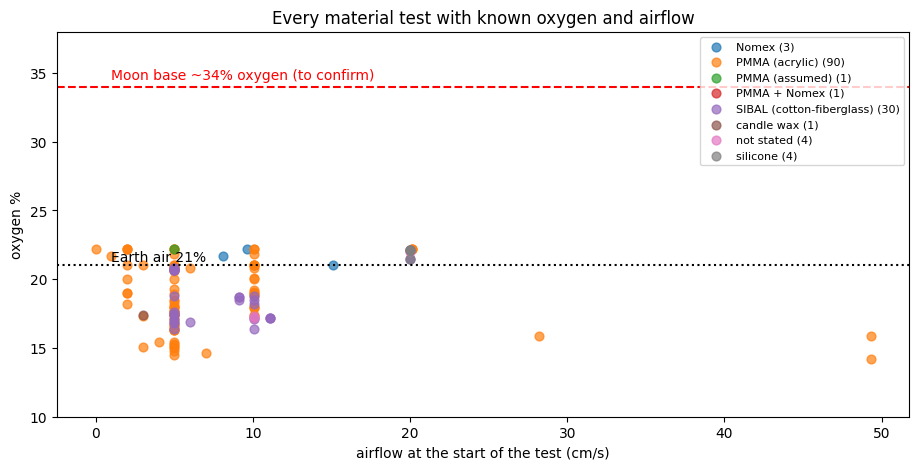

In [13]:
# Step 7: check by eye. Tests per material, and where they sit on oxygen x airflow (the start of our gap map).
import matplotlib.pyplot as plt
print(pd.crosstab(clean.material, clean.experiment).to_string(), "\n")
fig, ax = plt.subplots(figsize=(11, 5))
for m, g in clean.dropna(subset=["oxygen_pct", "airflow_start_cm_s"]).groupby("material"):
    ax.scatter(g.airflow_start_cm_s, g.oxygen_pct, label=f"{m} ({len(g)})", alpha=0.7, s=40)
ax.axhline(34, color="r", ls="--"); ax.text(1, 34.5, "Moon base ~34% oxygen (to confirm)", color="r")
ax.axhline(21, color="k", ls=":"); ax.text(1, 21.3, "Earth air 21%")
ax.set_xlabel("airflow at the start of the test (cm/s)"); ax.set_ylabel("oxygen %"); ax.set_ylim(10, 38)
ax.set_title("Every material test with known oxygen and airflow"); ax.legend(fontsize=8, loc="upper right")
plt.show()


## 8. Save

In [14]:
# Step 8: save the clean table. Download it from the Files panel (left), or the repo keeps a copy in data/.
clean.to_csv("material_tests.csv", index=False)
print("saved material_tests.csv:", len(clean), "rows x", len(clean.columns), "columns")


saved material_tests.csv: 263 rows x 16 columns
